# Metal demand by scenario

The scenario metal-demand cube built by the `calculate_metal_demand` rule
(`build/scenario_metal_demand.nc`, variable `metal_demand_kt` over dimensions
`(scenario, metal, technology)`): cumulative demand over the study window for
the metals the LCI datasets cover.

One panel per metal, one stacked bar per scenario, each bar broken down by the
technology the demand comes from. Bars are clustered by the group each scenario
claims (`scenarios.<name>.group` in `config/default.yaml`), the blocks drawn in
`scenario_groups` order and separated by a whitespace gap. Panels carry their own
y-axis — the metals span several orders of magnitude (aluminium in the thousands
of kt, dysprosium in single kt), so a shared axis would flatten most of them to
nothing. Compare bars *within* a panel, not across panels.

Display names and colours come from `technology_info` in `config/default.yaml`,
keyed by the same machine key as the cube, so the config stays the single
source of truth for naming and colour; scenario bar labels come from each
scenario's `nice_name`.

Run by the `visualise_metal_demand` snakemake rule, or interactively (paths
then resolve relative to the repo root).

In [1]:
import sys
from pathlib import Path

import pandas as pd
import xarray as xr
import yaml

# Snakemake runs this from the repo root, an interactive session from
# notebooks/; neither puts scripts/ on the path, so do it by hand.
repo = Path.cwd() if (Path.cwd() / "snakefile").exists() else Path.cwd().parent
sys.path.insert(0, str(repo / "scripts"))

import plotting  # noqa: E402
from utils import get_mineral_groups  # noqa: E402
from info_schemas import MineralInfo  # noqa: E402

try:
    paths = {
        "metal_demand": snakemake.input.metal_demand,  # type: ignore
        "mineral_info": snakemake.input.mineral_info,  # type: ignore
        "figures": snakemake.output.figures,  # type: ignore
    }
    technology_info = dict(snakemake.params.technology_info)  # type: ignore
    scenario_info = dict(snakemake.params.scenario_info)  # type: ignore
    scenario_groups = dict(snakemake.params.scenario_groups)  # type: ignore
    mineral_groups = dict(snakemake.params.mineral_groups)  # type: ignore
    style = dict(snakemake.params.plotting)  # type: ignore
except NameError:  # interactive run
    with open(repo / "config/default.yaml") as f:
        config = yaml.safe_load(f)
    technology_info = config["technology_info"]
    scenario_info = config["scenarios"]
    scenario_groups = config["scenario_groups"]
    mineral_groups = get_mineral_groups(config, repo / "data/mineral_info.csv")
    style = config["plotting"]
    paths = {
        "metal_demand": repo / "build/metal_demand/metal_demand.nc",
        "mineral_info": repo / "data/mineral_info.csv",
        "figures": repo / "build/metal_demand/figures",
    }

figures_dir = Path(paths["figures"])
figures_dir.mkdir(parents=True, exist_ok=True)
plotting.apply_style(style)

# Machine key -> display name / colour, in config order (sets stack + legend order).
nice_names = {t: info["nice_name"] for t, info in technology_info.items()}
colors = {t: info["color"] for t, info in technology_info.items()}
scenario_nice = {s: info["nice_name"] for s, info in scenario_info.items()}
scenario_group_nice = {g: info["nice_name"] for g, info in scenario_groups.items()}
group_nice = {g: info["nice_name"] for g, info in mineral_groups.items()}

In [2]:
demand = xr.open_dataset(paths["metal_demand"])["metal_demand_kt"]

# Config order for the stack; the cube carries the scenarios keyed by their config
# machine key (calculate_metal_demand reindexes to `list(config["scenarios"])`).
technologies = [t for t in technology_info if t in set(demand["technology"].values)]

# Technologies that never contribute (no sub-technologies yet, or an intensity of
# zero) would only add dead legend entries.
used = [t for t in technologies if float(abs(demand.sel(technology=t)).sum()) > 0]

# Likewise metals no technology draws on: an empty panel says nothing.
metals = [
    m for m in demand["metal"].values if float(abs(demand.sel(metal=m)).sum()) > 0
]

# Bars are blocked by each scenario's own `group`, the blocks in `scenario_groups`
# order and the scenarios within one in config order.
cube_scenarios = set(demand["scenario"].values)
present = [s for s in scenario_info if s in cube_scenarios]
unconfigured = sorted(cube_scenarios - set(present))
if unconfigured:
    raise ValueError(f"cube scenarios missing from config `scenarios`: {unconfigured}")
group_members = plotting.grouped_members(
    present, {s: info["group"] for s, info in scenario_info.items()}, scenario_groups
)
scenarios = [s for members in group_members.values() for s in members]
positions = plotting.bar_positions(group_members, style)

print(f"{len(metals)} metals x {len(scenarios)} scenarios x {len(used)} technologies")
print("dropped (no demand): "
      f"metals {sorted(set(demand['metal'].values) - set(metals))}, "
      f"technologies {sorted(set(technologies) - set(used))}")
for group_key, members in group_members.items():
    print(f"{scenario_group_nice[group_key]:>20}: {', '.join(scenario_nice[s] for s in members)}")
demand

24 metals x 13 scenarios x 15 technologies
dropped (no demand): metals [], technologies []
           Reference: Reference
             Battery: EV Na-ion push, EV NMC-811 push, EV LFP push
         Magnet REEs: Wind pull, EV induction motor push, Wind magnet pull
 Solar/semiconductor: Solar pull, Silicon PV push
      Grid conductor: Grid aluminium push
     Pt group metals: PEM electrolyser pull
             General: H2 and V2G, Nuclear push


<xarray.DataArray 'metal_demand_kt' (scenario: 13, metal: 24, technology: 15)> Size: 37kB
[4680 values with dtype=float64]
Coordinates:
  * scenario    (scenario) <U19 988B 'base' 'na_ion_push' ... 'pem_pull'
  * metal       (metal) <U12 1kB 'Aluminium' 'Cadmium' ... 'Tin' 'Vanadium'
  * technology  (technology) <U17 1kB 'ccgt' 'ev_battery' ... 'utility_solar'

In [3]:
# End-use grouping of the metals (Battery, Magnet REEs, Grid/conductor, ...).
# `Helper` rows are supply-side hosts and aggregates, so they carry no demand and
# drop out of the intersection with the cube on their own.
mineral_info = pd.read_csv(paths["mineral_info"])
group_of = dict(zip(mineral_info[MineralInfo.mineral], mineral_info[MineralInfo.group]))
order_of = {m: i for i, m in enumerate(mineral_info[MineralInfo.mineral])}


def base_mineral(metal):
    """The mineral_info row a cube metal belongs to.

    The LCI splits graphite by production route (`Graphite`, `Graphite
    (synthetic)`), which mineral_info carries as the one metal `Graphite` —
    the split is a route, not a different element, so the base name before
    any bracket puts both routes in their metal's group.
    """
    base = metal.split(" (")[0]
    if metal in group_of:
        return metal
    if base in group_of:
        return base
    raise KeyError(f"{metal!r} (or {base!r}) has no row in mineral_info.csv")


# Group order and within-group order both follow mineral_info, so the figure
# stays in step with the CSV rather than with an order hardcoded here.
grouped = {}
for metal in sorted(metals, key=lambda m: order_of[base_mineral(m)]):
    grouped.setdefault(group_of[base_mineral(metal)], []).append(metal)

for group, group_metals in grouped.items():
    print(f"{group_nice[group]:>20}: {', '.join(group_metals)}")

      Grid/conductor: Aluminium, Copper
       Semiconductor: Cadmium, Gallium, Germanium, Indium, Selenium, Tellurium
             Battery: Cobalt, Graphite, Lithium
         Magnet REEs: Dysprosium, Neodymium, Praseodymium, Terbium
    H2/PGM catalysts: Iridium, Platinum
       Bulk/dual-use: Manganese, Molybdenum, Nickel, Niobium, Vanadium
     Contacts/solder: Silver, Tin


## Demand per metal

Each panel is one metal. The bar height is that metal's total demand across the
whole system in kt; the segments are the technologies driving it, stacked in
config order. The number above each bar is the total.

Panels are laid out one row per end-use group (`group` in
`data/mineral_info.csv`), so the metals that rise and fall together — the
battery metals under a chemistry switch, the magnet REEs under a generator
switch — sit side by side.

Along each panel's x-axis the scenario bars are clustered by the group each one
claims (`scenarios.<name>.group`), separated by a whitespace gap, so the
scenarios that push on the same material — the battery-chemistry variants, the
wind/magnet variants — read as a block.

In [4]:
# Bars run along x: thirteen scenario names will not stand under a panel a
# third of the page wide, but they read level down a y axis.
PANEL_COLUMNS = 3
# The spec whose bars lie on their side, so its names are level: slanted, each
# would descend across the name below it.
PANEL_KEY = "metal_panel"


def stacked_by_technology(ax, metal, technologies=used):
    """One stacked bar per scenario for `metal`, split by technology.

    Scenarios are clustered by end-use group: same-group bars sit adjacent with
    a whitespace gap between groups (positions come from `positions`).
    `technologies` selects (and orders) the stack segments.
    """
    frame = (
        demand.sel(metal=metal)
        .to_series()
        .unstack("technology")
        .reindex(index=scenarios, columns=technologies)
        .fillna(0.0)
    )
    end = plotting.stacked_bars(
        ax, positions, frame, colors, style,
        panel_key=PANEL_KEY, orientation="horizontal",
    )

    for scenario, total in zip(scenarios, end):
        ax.text(total + 0.02 * end.max(), positions[scenario], f"{total:,.3g}",
                ha="left", va="center", color=style["ink"]["muted"])

    plotting.style_panel(
        ax, style, title=metal, ylabel="kt", orientation="horizontal",
        title_loc="center",
    )
    plotting.category_axis(
        ax, positions, scenario_nice, style, panel_key=PANEL_KEY,
        orientation="horizontal",
    )
    ax.set_xlim(0, 1.32 * end.max())  # headroom for the total beside each bar
    plotting.compact_ticks(ax, style, PANEL_KEY, "horizontal")


def technology_legend(target, technologies=used, ncol=1, **placement):
    """Technology key, reversed so it reads top-down like the stack.

    `target` is a figure (shared key under a grid) or an axes (key beside a
    single panel); `technologies` matches the stack drawn; `placement` is
    passed through to its .legend().
    """
    return target.legend(
        handles=plotting.patch_handles(reversed(technologies), colors, nice_names),
        title="Technology", frameon=False, ncol=ncol, **placement,
    )


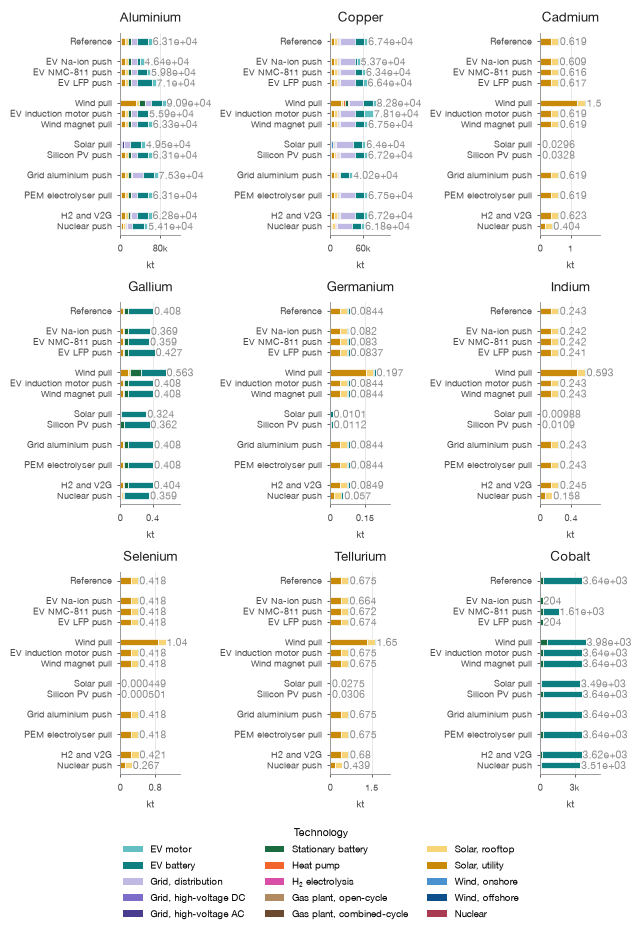

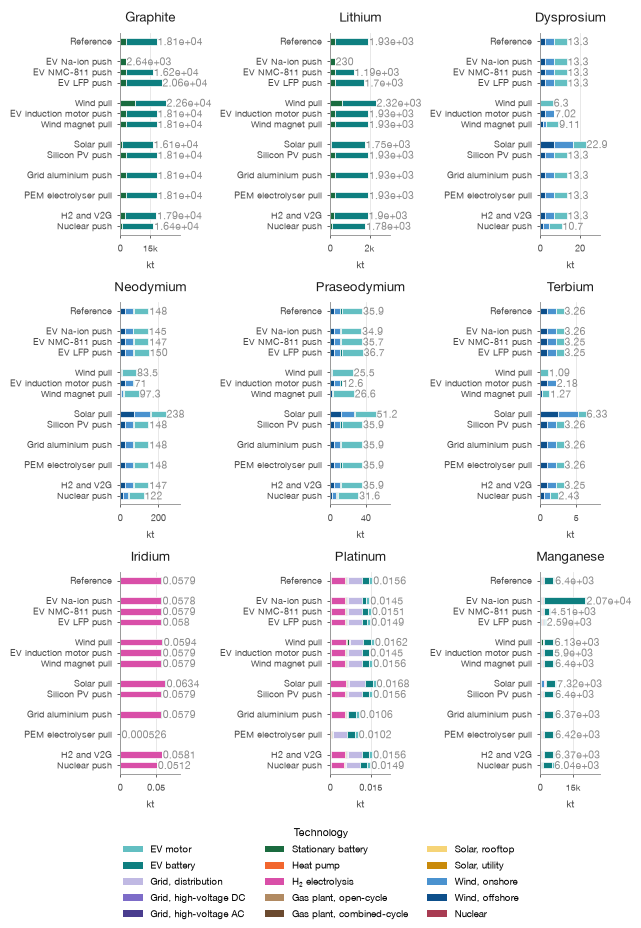

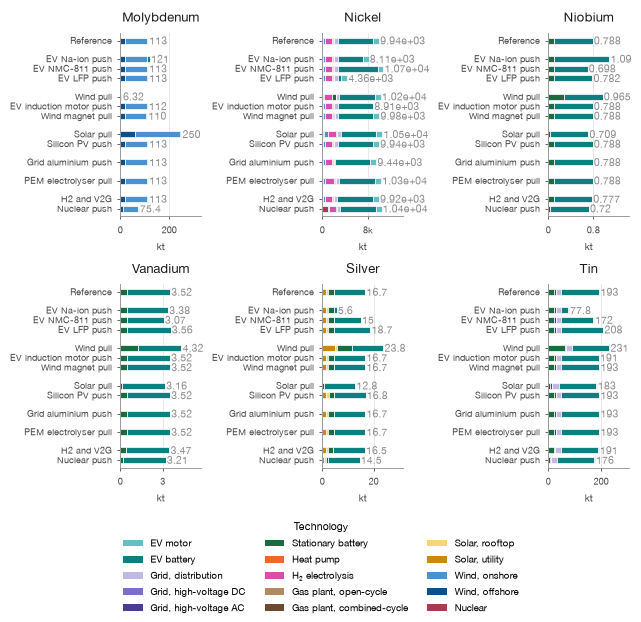

In [5]:
# Metals in end-use order, flowed across the pages: a row per group would cost
# more pages, and the grouping survives in the panel order.
ordered_metals = [metal for members in grouped.values() for metal in members]

for page, (fig, axes, page_metals) in enumerate(
    plotting.paged_grid(
        ordered_metals,
        style,
        max_columns=PANEL_COLUMNS,
        row_height=plotting.bar_panel_height(len(scenarios), style),
    ),
    start=1,
):
    for ax, metal in zip(axes, page_metals):
        stacked_by_technology(ax, metal)
    legend = technology_legend(
        fig, ncol=3, loc="outside lower center",
    )
    plotting.save_figure(fig, figures_dir, f"metal_demand_kt_{page}", style, (legend,))


## Inspecting the numbers behind a panel

The figure only shows shape; these helpers put the same cube values on screen as
tables, one metal at a time (scenarios down, technologies across), so a bar can
be traced back to the technologies making it up and to the scenario it moves
against.

In [6]:
demand.sel(technology="heat_pump", scenario="base").to_dataframe()

,scenario,technology,metal_demand_kt
metal,,,
Aluminium,base,heat_pump,6.189719e+01
Cadmium,base,heat_pump,0.000000e+00
Cobalt,base,heat_pump,2.678282e-03
Copper,base,heat_pump,2.100017e+03
Dysprosium,base,heat_pump,4.140887e-05
Gallium,base,heat_pump,9.055244e-10
Germanium,base,heat_pump,0.000000e+00
Graphite,base,heat_pump,2.038445e-05
Indium,base,heat_pump,0.000000e+00


In [7]:
demand.sel(technology="ocgt", scenario="base").to_dataframe()

,scenario,technology,metal_demand_kt
metal,,,
Aluminium,base,ocgt,8.613817e+01
Cadmium,base,ocgt,0.000000e+00
Cobalt,base,ocgt,2.715890e-04
Copper,base,ocgt,1.015462e+02
Dysprosium,base,ocgt,5.645788e-06
Gallium,base,ocgt,3.348886e-10
Germanium,base,ocgt,0.000000e+00
Graphite,base,ocgt,1.172919e-06
Indium,base,ocgt,0.000000e+00


In [8]:
def demand_table(metal, drop_empty=True, relative_to=None):
    """Cube slice for `metal` as a frame: scenarios down, technologies across.

    Rows and columns follow the figure's order (`scenarios`, `used`) so the
    table reads like the panel. `Total` is the bar height. `drop_empty` hides
    technologies that never touch this metal — most metals are drawn by two or
    three of the thirteen. `relative_to` a scenario key subtracts that
    scenario's row, which is how a push shows up: everything is zero except the
    technologies the switch actually moved.
    """
    frame = (
        demand.sel(metal=metal)
        .to_series()
        .unstack("technology")
        .reindex(index=scenarios, columns=used)
        .fillna(0.0)
    )
    if drop_empty:
        frame = frame.loc[:, (frame != 0).any()]
    if relative_to is not None:
        frame = frame - frame.loc[relative_to]
    frame["Total"] = frame.sum(axis=1)
    return frame.rename(index=scenario_nice, columns=nice_names)


pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

demand_table("Iridium").round(4)

technology,H₂ electrolysis,Stationary battery,EV battery,Total
scenario,,,,
Reference,0.0574,0.0001,0.0004,0.0579
EV Na-ion push,0.0574,0.0001,0.0003,0.0578
EV NMC-811 push,0.0574,0.0001,0.0004,0.0579
EV LFP push,0.0574,0.0001,0.0005,0.0580
Wind pull,0.0588,0.0002,0.0004,0.0594
EV induction motor push,0.0574,0.0001,0.0004,0.0579
Wind magnet pull,0.0574,0.0001,0.0004,0.0579
Solar pull,0.0629,0.0000,0.0004,0.0634
Silicon PV push,0.0574,0.0001,0.0004,0.0579


In [9]:
# Deltas against the reference scenario: what each push actually shifts.
demand_table("Platinum", relative_to="base").round(5)

technology,Nuclear,"Gas plant, combined-cycle","Gas plant, open-cycle",H₂ electrolysis,Heat pump,Stationary battery,"Grid, high-voltage AC","Grid, high-voltage DC","Grid, distribution",EV battery,EV motor,Total
scenario,,,,,,,,,,,,
Reference,0.00000,0.00000,0.00000,0.00000,0.0,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000
EV Na-ion push,0.00000,0.00000,0.00000,0.00000,0.0,0.00000,0.00000,0.00000,0.00000,-0.00109,0.00000,-0.00109
EV NMC-811 push,0.00000,0.00000,0.00000,0.00000,0.0,0.00000,0.00000,0.00000,0.00000,-0.00048,0.00000,-0.00048
EV LFP push,0.00000,0.00000,0.00000,0.00000,0.0,0.00000,0.00000,0.00000,0.00000,-0.00072,0.00000,-0.00072
Wind pull,0.00004,0.00003,-0.00000,0.00013,-0.0,0.00061,-0.00001,-0.00005,-0.00012,0.00000,0.00000,0.00062
EV induction motor push,0.00000,0.00000,0.00000,0.00000,0.0,0.00000,0.00000,0.00000,0.00000,0.00000,-0.00112,-0.00112
Wind magnet pull,0.00000,0.00000,0.00000,0.00000,0.0,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000
Solar pull,0.00001,-0.00002,-0.00001,0.00052,0.0,-0.00027,0.00004,0.00021,0.00076,0.00000,0.00000,0.00124
Silicon PV push,0.00000,0.00000,0.00000,0.00000,0.0,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000


In [10]:
# Every panel's bar heights at once: metals across, scenarios down. Columns keep
# the figure's grouped metal order, so this reads as the whole grid collapsed to
# its totals.
totals = (
    demand.sum("technology")
    .to_series()
    .unstack("metal")
    .reindex(index=scenarios, columns=[m for ms in grouped.values() for m in ms])
    .rename(index=scenario_nice)
)
totals.round(3)

metal,Aluminium,Copper,Cadmium,Gallium,Germanium,Indium,Selenium,Tellurium,Cobalt,Graphite,Lithium,Dysprosium,Neodymium,Praseodymium,Terbium,Iridium,Platinum,Manganese,Molybdenum,Nickel,Niobium,Vanadium,Silver,Tin
scenario,,,,,,,,,,,,,,,,,,,,,,,,
Reference,63143.375,67444.318,0.619,0.408,0.084,0.243,0.418,0.675,3640.235,18137.723,1927.107,13.290,147.676,35.928,3.256,0.058,0.016,6402.633,113.434,9939.006,0.788,3.519,16.722,193.050
EV Na-ion push,46423.731,53690.038,0.609,0.369,0.082,0.242,0.418,0.664,203.662,2642.829,230.095,13.293,144.567,34.930,3.258,0.058,0.015,20718.469,120.787,8106.411,1.086,3.376,5.598,77.838
EV NMC-811 push,59783.177,63416.143,0.616,0.359,0.083,0.242,0.418,0.672,1606.926,16239.461,1186.664,13.286,146.941,35.703,3.254,0.058,0.015,4510.695,113.021,10704.638,0.698,3.071,14.977,172.288
EV LFP push,71004.013,66362.230,0.617,0.427,0.084,0.241,0.418,0.674,204.319,20611.070,1697.758,13.288,149.936,36.697,3.255,0.058,0.015,2594.123,113.406,4361.062,0.782,3.557,18.710,208.220
Wind pull,90946.253,82840.477,1.504,0.563,0.197,0.593,1.044,1.648,3984.419,22630.142,2316.272,6.305,83.463,25.460,1.085,0.059,0.016,6126.443,6.316,10214.676,0.965,4.321,23.785,231.153
EV induction motor push,55916.456,78102.326,0.619,0.408,0.084,0.243,0.418,0.675,3640.224,18137.723,1927.107,7.021,70.959,12.589,2.184,0.058,0.014,5901.882,112.107,8905.415,0.788,3.519,16.689,191.070
Wind magnet pull,63285.992,67533.485,0.619,0.408,0.084,0.243,0.418,0.675,3640.235,18137.723,1927.107,9.110,97.348,26.649,1.267,0.058,0.016,6399.187,109.988,9980.449,0.788,3.519,16.722,193.050
Solar pull,49544.413,64030.947,0.030,0.324,0.010,0.010,0.000,0.028,3487.118,16139.059,1753.968,22.856,238.406,51.176,6.334,0.063,0.017,7316.772,249.620,10497.391,0.709,3.161,12.806,183.201
Silicon PV push,63143.375,67166.076,0.033,0.362,0.011,0.011,0.001,0.031,3640.235,18137.723,1927.107,13.290,147.676,35.928,3.256,0.058,0.016,6402.633,113.434,9939.006,0.788,3.519,16.834,193.050
